In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model, k_risk

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc

# Loading in data

## Using PROVIDE Project scenarios
Robin Lamboll, Joeri Rogelj, & Carl-Friedrich Schleussner. (2025). Scenario emissions and temperature data for PROVIDE project (v1.3.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.11108741

https://pure.iiasa.ac.at/id/eprint/18130/1/essoar.10511875.2.pdf for description

https://zenodo.org/records/11108741 for actual data set

In [2]:
folder = '../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values

## GTPR2025 Tipping elements

In [3]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

# Simulations

In [5]:
scenarios

array(['CurPol_SAP', 'CurPol_OS_1.5C', 'ModAct_OS_1.5C', 'ModAct_OS_1C',
       'ModAct_SAP', 'ssp534-over', 'Neg_SAP', 'GS_NZGHG', 'Ren_NZCO2',
       'Neg_NZGHG', 'Ref_1p5', 'Neg_OS_0C', 'LD_NZGHG', 'SP_NZGHG',
       'ssp119'], dtype=object)

In [109]:
baseline = 'CurPol_OS_1.5C'
temp = df[baseline].to_numpy()
t_ref=2015
T_ref=temp[t_ref-1850]
T_max=temp.max()
xdata = np.arange(t_ref,2301)-t_ref
ydata=temp[t_ref-1850:]
popt, pcov = curve_fit(OS_model, xdata, ydata,
                       p0=[T_ref, T_max, temp[-1], (T_max-T_ref)/0.01, 10 ,(temp.max()-T_ref)/0.01],
                       bounds = ([T_ref-0.5, T_max-0.5, temp[-1]-0.5, 10, 0, 10],
                                 [T_ref+0.5, T_max+0.5, temp[-1]+0.5, len(ydata), 100, len(ydata)]) )

print(popt)

[  1.10009253   3.30206671   1.50422    103.28176816   3.44043629
 163.72772189]


In [110]:
years_burn_in = np.arange(1850,2016) # up to and including 2015
no_burn_years = len(years_burn_in)
pc_burn = np.ones((no_burn_years,len(df_TEs)))
pc_burn *= q_c
pr_burn = np.ones((no_burn_years,len(df_TEs)))
pr_burn *= q_r
for t in years_burn_in-1850:
    pc_burn[t,:] *= temp_response(temp[t], T_lim, betas)
    pr_burn[t,:] *= (1-temp_response(temp[t], T_lim, betas))

D_burn = np.zeros((len_sample,len(df_TEs)))
D_burn_noint = np.zeros(len(df_TEs))

for r in tqdm.tqdm(range(len_sample)):
    for t in range(1,no_burn_years):
        D_burn[r,:] = environmental_update(D_burn[r,:],
                                           A[r],
                                           pc=pc_burn[t,:],
                                           pr=pr_burn[t,:])
for t in tqdm.tqdm(range(1,no_burn_years)):
    D_burn_noint = environmental_update(D_burn_noint,
                                        np.zeros((len(df_TEs),len(df_TEs))),
                                        pc=pc_burn[t,:],
                                        pr=pr_burn[t,:])

100%|██████████████████████████████████████| 165/165 [00:00<00:00, 91156.50it/s]


## T_peak x T_OS

In [111]:
T_peaks = np.arange(0,5.1,step=0.1) # change step to 0.2 for faster
T_oss = np.arange(0,3.1,step=0.1)

years = np.arange(2015,2301)
no_years=len(years)

In [112]:
# pcs = np.ones((len(T_peaks), len(T_oss), no_years, len(df_TEs)))
# prs = np.ones((len(T_peaks), len(T_oss), no_years, len(df_TEs)))
D = np.zeros((len(T_peaks), len(T_oss), no_years, len(df_TEs)))
d_samps = np.zeros((len_sample,no_years,len(df_TEs)))
d_samps[:,0,:] = D_burn
# D[:,:,]
temps = np.ones((len(T_peaks), len(T_oss), no_years))
PAR = np.copy(popt)
for i in tqdm.tqdm(range(T_peaks.shape[0])):
    for j in range(T_oss.shape[0]): # T_os can only be less than T_peak
        # if T_oss[j] <= T_peaks[i]:
        PAR[1:3] = [T_peaks[i], T_oss[j]]
        temps[i,j,:] = OS_model(xdata,*PAR)
        D[i,j,0,:] = D_burn.mean(axis=0)
        for t in range(1,no_years):
            pc = q_c*temp_response(temps[i,j,t], T_lim, betas)
            pr = q_r*(1- temp_response(temps[i,j,t], T_lim, betas))
            for r in range(len_sample):
                d_samps[r,t,:] = environmental_update(d_samps[r,t-1,:], A[r],pc=pc,pr=pr)
        D[i,j,:,:] = d_samps.mean(axis=0)
                # D[i,j,t,:] = environmental_update(D[i,j,r,t-1,:], 
                #                                     A[r], 
                #                                     pc = pcs[i,j,t,:],
                #                                     pr = prs[i,j,t,:])

100%|███████████████████████████████████████████| 51/51 [20:15<00:00, 23.83s/it]


In [113]:
D_nr = np.delete(D,6,axis=-1)
AR_popt = np.array([k_risk(D_nr[:,:,-1,:],k,axis=2) 
                     for k in range(1,D_nr.shape[-1]+1)]) 
# R_data = np.array([np.max(pars[i].reshape(1,
#                                           len(pars[i]),1)*(AR_popt[i]<=0.1), 
#                           axis=1) 
#                    for i in range(6)]) # R_data to differentiate with r_data

In [117]:
AR_popt.shape

(8, 51, 31)

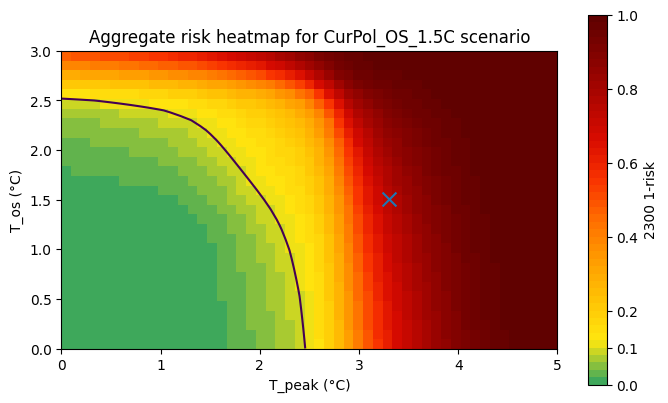

In [115]:
T_Pg,T_Og = np.meshgrid(T_peaks,T_oss)
fig,ax = plt.subplots(figsize=(8,6))

mask = np.zeros_like(T_Pg)#(T_Og>T_Pg)
to_plot = np.ma.array(AR_popt[0,:,:].transpose(),mask=mask)

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=50).with_extremes(bad='white')

ax.plot([0,0],[3,3],color='k')
ax.scatter(popt[1],popt[2],marker='x',s=100)
im=ax.imshow(to_plot,cmap=cmap,#cmap='Reds',
              extent=(T_peaks[0], T_peaks[-1], T_oss[0], T_oss[-1]),
              origin='lower',vmin=0,vmax=1,zorder=0)
fig.colorbar(im,shrink=0.8,label='2300 1-risk',ticks=[0,0.1,0.2,0.4,0.6,0.8,1])
CS = plt.contour(T_Pg, T_Og, to_plot,
                 [0.1],corner_mask=True)
# plt.clabel(CS)
ax.set_xlabel('T_peak (°C)')
ax.set_ylabel('T_os (°C)')
ax.set_title('Aggregate risk heatmap for %s scenario'%baseline)
# plt.colorbar(im)

fig.savefig('../../Figures/Overshoots/perturb_around_baseline/2d_variations_%s.png'%baseline,bbox_inches='tight')

In [98]:
popt

array([ 1.08741336,  2.31898889,  1.45509682, 37.55081543,  9.41345871,
       81.42360056])

In [71]:
T_Og

array([[0. , 0. , 0. , ..., 0. , 0. , 0. ],
       [0.2, 0.2, 0.2, ..., 0.2, 0.2, 0.2],
       [0.4, 0.4, 0.4, ..., 0.4, 0.4, 0.4],
       ...,
       [4.6, 4.6, 4.6, ..., 4.6, 4.6, 4.6],
       [4.8, 4.8, 4.8, ..., 4.8, 4.8, 4.8],
       [5. , 5. , 5. , ..., 5. , 5. , 5. ]], shape=(26, 51))

In [43]:
colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
len(c_list)

10

In [33]:
lower_mask.shape

(51, 26)

In [29]:
T_oss.shape

(26,)

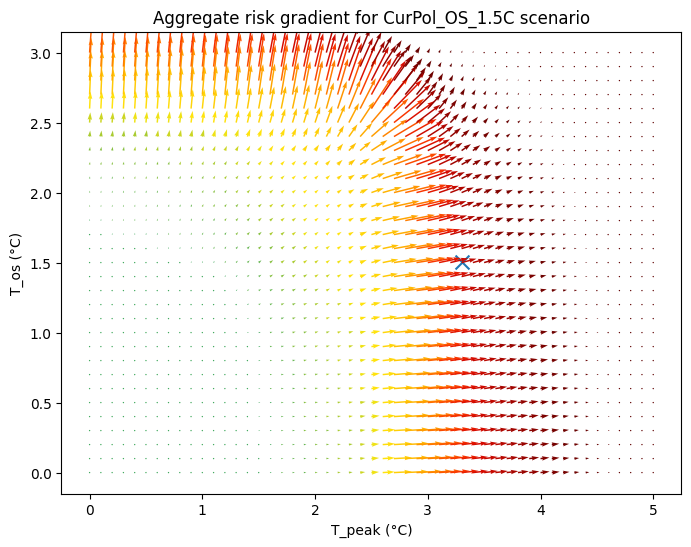

In [116]:
fig,ax = plt.subplots(figsize=(8,6))

mask = np.zeros_like(T_Pg)#(T_Og>T_Pg)
to_plot = np.gradient(AR_popt[0,:,:]) #np.ma.array(AR_popt[0,:,:].transpose(),mask=mask)

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=50).with_extremes(bad='white')

T_Og,T_Pg = np.meshgrid(T_oss,T_peaks)
ax.plot([0,0],[3,3],color='k')
ax.scatter(popt[1],popt[2],marker='x',s=100)
im=ax.quiver(T_Pg, T_Og,to_plot[0],to_plot[1],AR_popt[0,:,:],cmap=cmap,)#cmap='Reds',
              # extent=(T_peaks[0], T_peaks[-1], T_oss[0], T_oss[-1]),
# fig.colorbar(im,shrink=0.8,label='2300 1-risk',ticks=[0,0.1,0.2,0.4,0.6,0.8,1])
# CS = plt.contour(T_Pg, T_Og, to_plot,
#                  [0.1],corner_mask=True)
# plt.clabel(CS)
ax.set_xlabel('T_peak (°C)')
ax.set_ylabel('T_os (°C)')
ax.set_title('Aggregate risk gradient for %s scenario'%baseline)
# plt.colorbar(im)

fig.savefig('../../Figures/Overshoots/perturb_around_baseline/2d_gradient_%s.png'%baseline,bbox_inches='tight')

## T_OS x t_down

In [5]:
popt

array([ 1.08741336,  2.31898889,  1.45509682, 37.55081547,  9.41345856,
       81.42360068])

In [60]:
T_oss = np.arange(0,2.4,step=0.1)
t_downs = np.arange(0,201,step=5)

years = np.arange(2015,2301)
no_years=len(years)

print(len(T_oss), len(t_downs))

24 41


In [61]:
# pcs = np.ones((len(T_peaks), len(T_oss), no_years, len(df_TEs)))
# prs = np.ones((len(T_peaks), len(T_oss), no_years, len(df_TEs)))
D = np.zeros((len(t_downs), len(T_oss), no_years, len(df_TEs)))
d_samps = np.zeros((len_sample,no_years,len(df_TEs)))
d_samps[:,0,:] = D_burn
# D[:,:,]
temps = np.ones((D.shape[:-1]))
PAR = np.copy(popt)
for i in tqdm.tqdm(range(t_downs.shape[0])):
    for j in range(T_oss.shape[0]): # T_os can only be less than T_peak
        # if T_oss[j] <= T_peaks[i]:
        PAR[[2,-1]] = [T_oss[j],t_downs[i]]
        temps[i,j,:] = OS_model(xdata,*PAR)
        D[i,j,0,:] = D_burn.mean(axis=0)
        for t in range(1,no_years):
            pc = q_c*temp_response(temps[i,j,t], T_lim, betas)
            pr = q_r*(1- temp_response(temps[i,j,t], T_lim, betas))
            for r in range(len_sample):
                d_samps[r,t,:] = environmental_update(d_samps[r,t-1,:], A[r],pc=pc,pr=pr)
        D[i,j,:,:] = d_samps.mean(axis=0)
                # D[i,j,t,:] = environmental_update(D[i,j,r,t-1,:], 
                #                                     A[r], 
                #                                     pc = pcs[i,j,t,:],
                #                                     pr = prs[i,j,t,:])

100%|███████████████████████████████████████████| 41/41 [12:46<00:00, 18.70s/it]


In [92]:
D_nr.shape

(41, 24, 286, 8)

In [91]:
AR_popt.shape

(41, 24, 286)

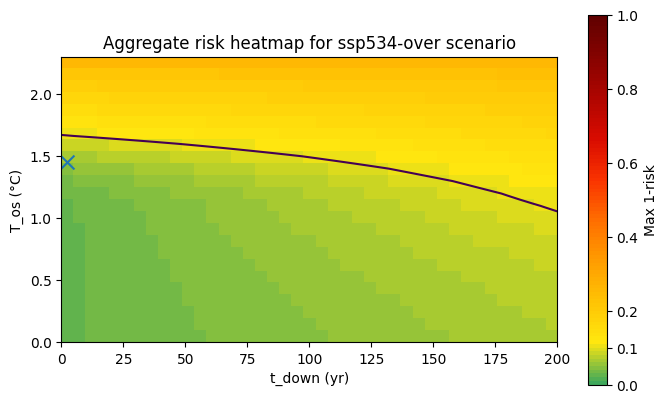

In [108]:
t_dg,T_og = np.meshgrid(t_downs,T_oss)
fig,ax = plt.subplots(figsize=(8,6))

mask = np.zeros_like(t_dg)#(T_Og>T_Pg)
to_plot = np.ma.array(AR_popt.max(axis=-1).transpose(),mask=mask)

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=100).with_extremes(bad='white')

# ax.plot([0,0],[3,3],color='k')
ax.scatter(popt[1],popt[2],marker='x',s=100)
im=ax.imshow(to_plot,cmap=cmap,#cmap='Reds',
              extent=(t_downs[0], t_downs[-1], T_oss[0], T_oss[-1]),
              origin='lower',vmin=0,vmax=1,zorder=0,aspect=50)
fig.colorbar(im,shrink=0.8,label='Max 1-risk',ticks=[0,0.1,0.2,0.4,0.6,0.8,1])
CS = plt.contour(t_dg, T_og, to_plot,
                 [0.1],corner_mask=True)
# plt.clabel(CS)
ax.set_xlabel('t_down (yr)')
ax.set_ylabel('T_os (°C)')
ax.set_title('Aggregate risk heatmap for %s scenario'%baseline)

fig.savefig('../../Figures/Overshoots/perturb_around_baseline/2d_variations_%s_Tos_td.png'%baseline,bbox_inches='tight')

In [70]:
dat0 = CS.allsegs[0][0]
ramp_contour = (popt[1]-dat0[:,1])/dat0[:,0]
print(dat0.shape)

(47, 2)


/tmp/ipykernel_94979/630080328.py:2: RuntimeWarning: divide by zero encountered in divide
  ramp_contour = (popt[1]-dat0[:,1])/dat0[:,0]


In [71]:
print(ramp_contour)

[       inf 0.13099506 0.06618284 0.04459072 0.03380328 0.0273378
 0.02303346 0.0199642  0.017667   0.01588463 0.01512887 0.01446899
 0.01332032 0.01236671 0.01156324 0.01087783 0.01028696 0.00977301
 0.00932247 0.00892486 0.00857192 0.00843775 0.00826889 0.00800505
 0.00776748 0.00755279 0.00735817 0.00718125 0.00702004 0.00695637
 0.00688986 0.00678188 0.00668198 0.00658935 0.00650327 0.00645784
 0.00643705 0.00639077 0.00634554 0.00630129 0.00627153 0.00626667
 0.00624933 0.0062294  0.0062072  0.00619953 0.00619809]


In [72]:
print((popt[1]-popt[2])/popt[-1])

0.010609848597396367


/tmp/ipykernel_94979/4003361894.py:1: RuntimeWarning: divide by zero encountered in divide
  plt.scatter((popt[1]-T_og[:,:])/t_dg[:,:], to_plot[:,:],


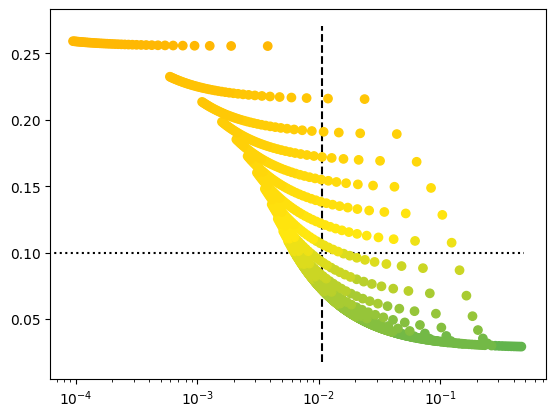

In [103]:
plt.scatter((popt[1]-T_og[:,:])/t_dg[:,:], to_plot[:,:],
            c=to_plot,cmap=cmap,vmin=0,vmax=1)
plt.plot(plt.gca().get_xlim(),[0.1]*2,c='k',ls=':',zorder=0)
plt.plot([(popt[1]-popt[2])/popt[-1]]*2,plt.gca().get_ylim(),c='k',ls='--',zorder=0)
# plt.yscale('log')
plt.xscale('log')

In [74]:
to_plot.shape

(24, 41)